In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np

from nonconvex_regression import (
    calculate_coefficient_recovery,
    calculate_rmse,
    clean_data,
    gamma_kde,
    lad,
    lp_irls,
    ols,
    outlier_data,
)

plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
n = 1000
beta = np.array([1.0, 1.0])
epsilon = 1e-1
x_min, x_max = -2, 2
lp = 0.2
eps = 1e-3
maxiter = 500

In [3]:
p_range = np.linspace(0.1, 0.5, 25)
A_range = np.linspace(10, 100, 25)
seed = 1


method_names = ("Lp-IRLS", "LAD", "OLS")
metric_names = ("Training RMSE", "Test RMSE", "Coefficient recovery error")
statistics = {
    method_name: {
        metric_name: np.zeros((len(p_range), len(A_range)))
        for metric_name in metric_names
    }
    for method_name in method_names
}
runtime_statistics = {
    method_name: np.zeros((len(p_range), len(A_range))) for method_name in method_names
}

# Generate each data set once so all methods see identical data and seeds.
seed_grid = (
    seed
    + 1
    + np.arange(len(p_range) * len(A_range)).reshape(len(p_range), len(A_range))
)
data_sweep = [[None for _ in A_range] for _ in p_range]
for p_index, p in enumerate(p_range):
    for A_index, A in enumerate(A_range):
        data_seed = seed_grid[p_index, A_index]
        clean_points = clean_data(n, beta, epsilon, x_min, x_max, data_seed)
        outlier_points = outlier_data(n, beta, epsilon, x_min, x_max, p, A, data_seed)
        data_sweep[p_index][A_index] = (clean_points, outlier_points)

fitting_methods = (
    ("Lp-IRLS", lambda X, y: lp_irls(X, y, lp, eps, maxiter=maxiter)),
    ("LAD", lad),
    ("OLS", ols),
)

# Separate passes keep estimator timings independent while reusing the same data.
for method_name, fit_method in fitting_methods:
    for p_index in range(len(p_range)):
        for A_index in range(len(A_range)):
            clean_points, outlier_points = data_sweep[p_index][A_index]
            fit_start = perf_counter()
            coefficients = fit_method(outlier_points[:, 0:1], outlier_points[:, 1])
            runtime_statistics[method_name][p_index, A_index] = (
                perf_counter() - fit_start
            )
            method_statistics = statistics[method_name]
            method_statistics["Training RMSE"][p_index, A_index] = calculate_rmse(
                outlier_points, coefficients
            )
            method_statistics["Test RMSE"][p_index, A_index] = calculate_rmse(
                clean_points, coefficients
            )
            method_statistics["Coefficient recovery error"][p_index, A_index] = (
                calculate_coefficient_recovery(coefficients, beta)
            )

for method_name in method_names:
    runtimes = runtime_statistics[method_name]
    print(
        f"{method_name}: total={runtimes.sum():.3f}s, "
        f"mean={runtimes.mean():.6f}s, "
        f"median={np.median(runtimes):.6f}s per fit"
    )

Lp-IRLS: total=7.038s, mean=0.011261s, median=0.011075s per fit
LAD: total=58.962s, mean=0.094339s, median=0.097893s per fit
OLS: total=0.032s, mean=0.000051s, median=0.000041s per fit


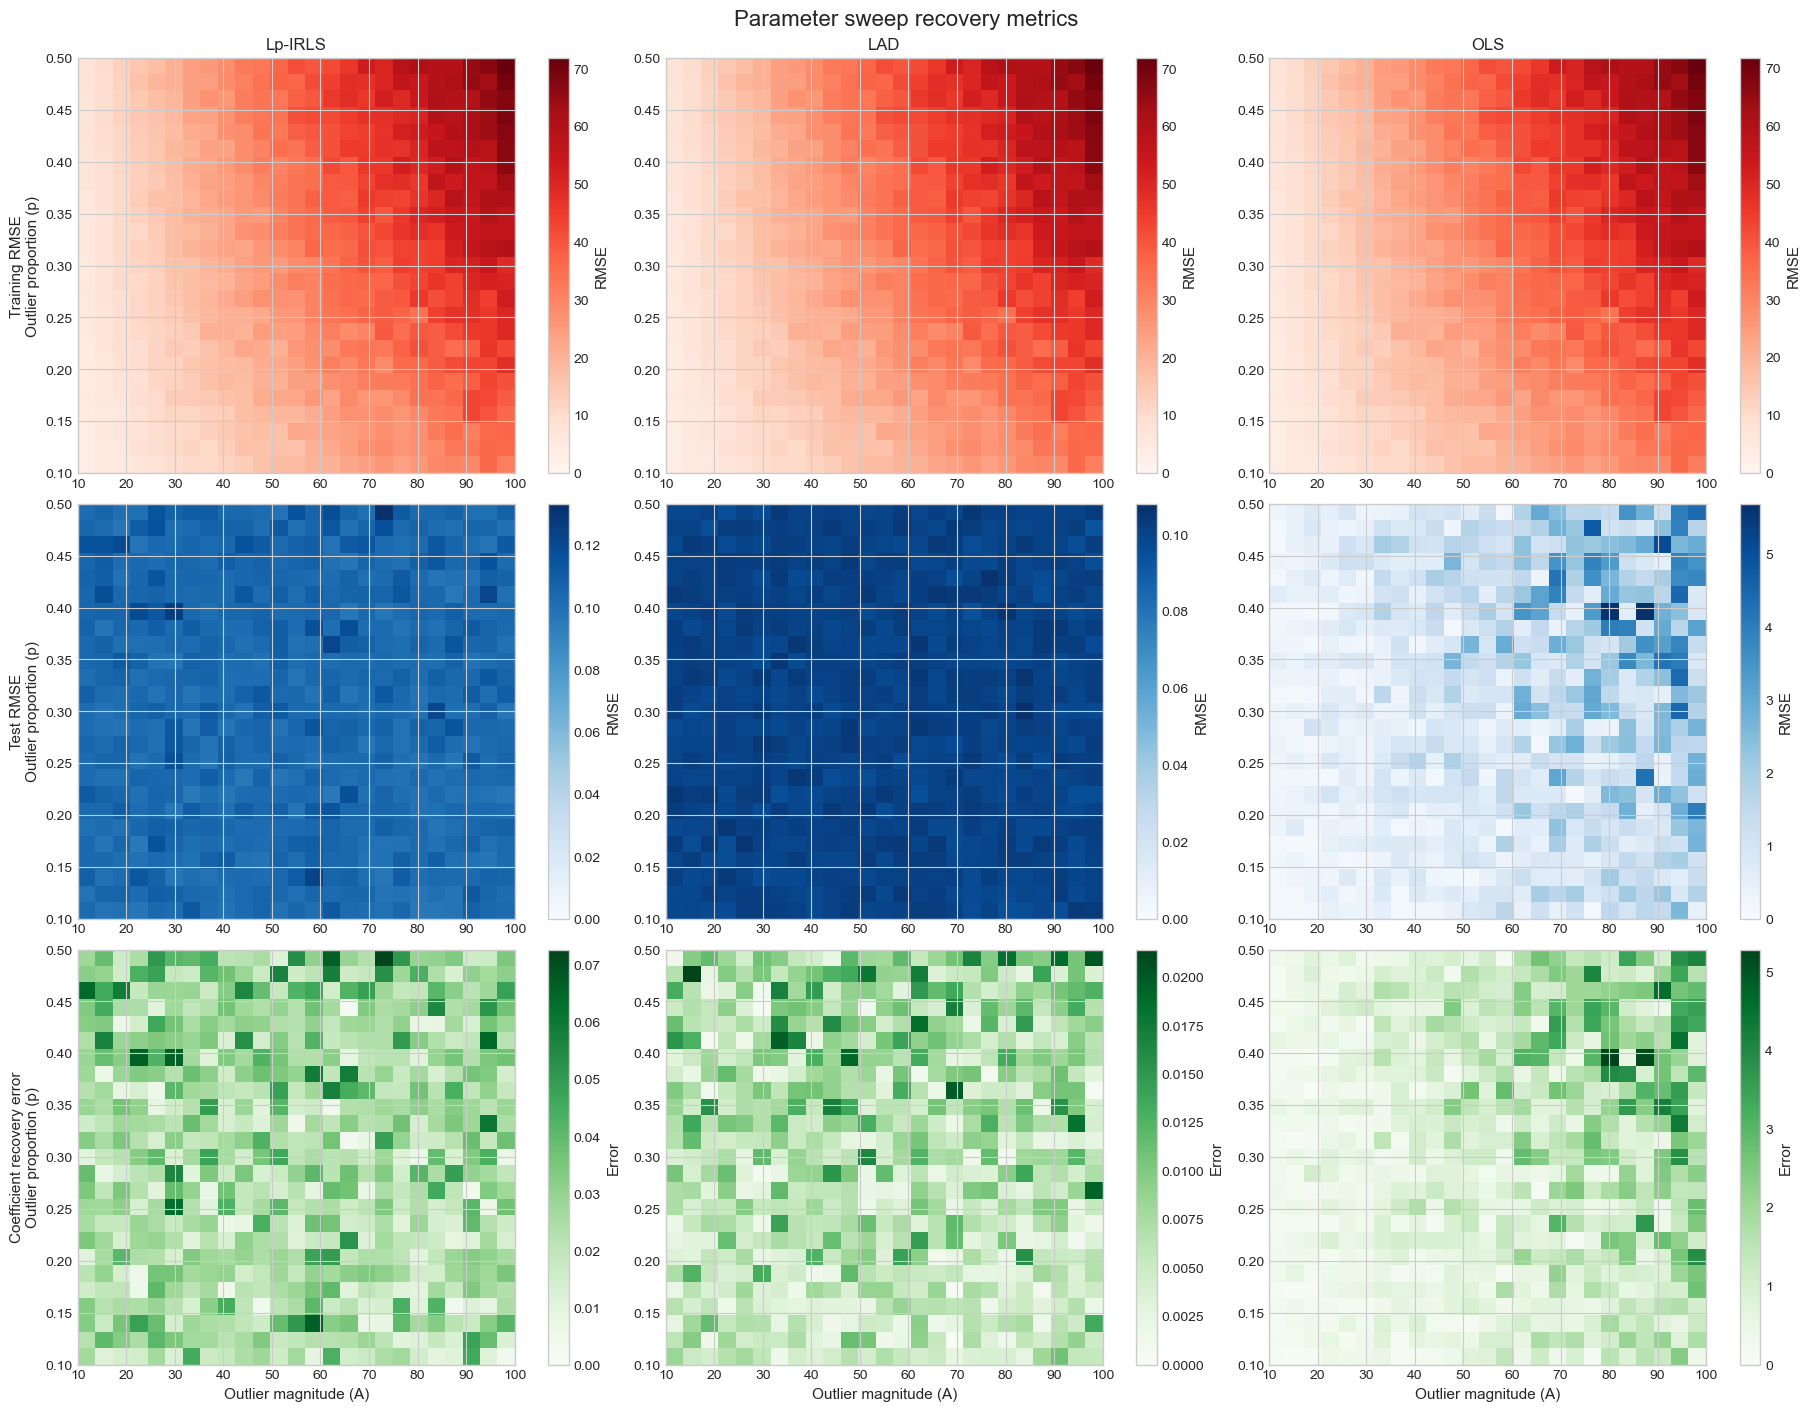

In [4]:
metric_plot_settings = (
    ("Training RMSE", "Reds", "RMSE"),
    ("Test RMSE", "Blues", "RMSE"),
    ("Coefficient recovery error", "Greens", "Error"),
)

fig, axes = plt.subplots(3, 3, figsize=(18, 14), constrained_layout=True)
fig.suptitle("Parameter sweep recovery metrics", fontsize=16)

for row_index, (metric_name, cmap, colorbar_label) in enumerate(metric_plot_settings):
    for column_index, method_name in enumerate(method_names):
        ax = axes[row_index, column_index]
        image = ax.imshow(
            statistics[method_name][metric_name],
            origin="lower",
            aspect="auto",
            extent=[A_range.min(), A_range.max(), p_range.min(), p_range.max()],
            cmap=cmap,
            interpolation="nearest",
            vmin=0,
        )
        if row_index == 0:
            ax.set_title(method_name, fontsize=12)
        if column_index == 0:
            ax.set_ylabel(f"{metric_name}\nOutlier proportion (p)", fontsize=11)
        if row_index == 2:
            ax.set_xlabel("Outlier magnitude (A)", fontsize=11)
        colorbar = fig.colorbar(image, ax=ax)
        colorbar.set_label(colorbar_label, fontsize=11)

plt.show()

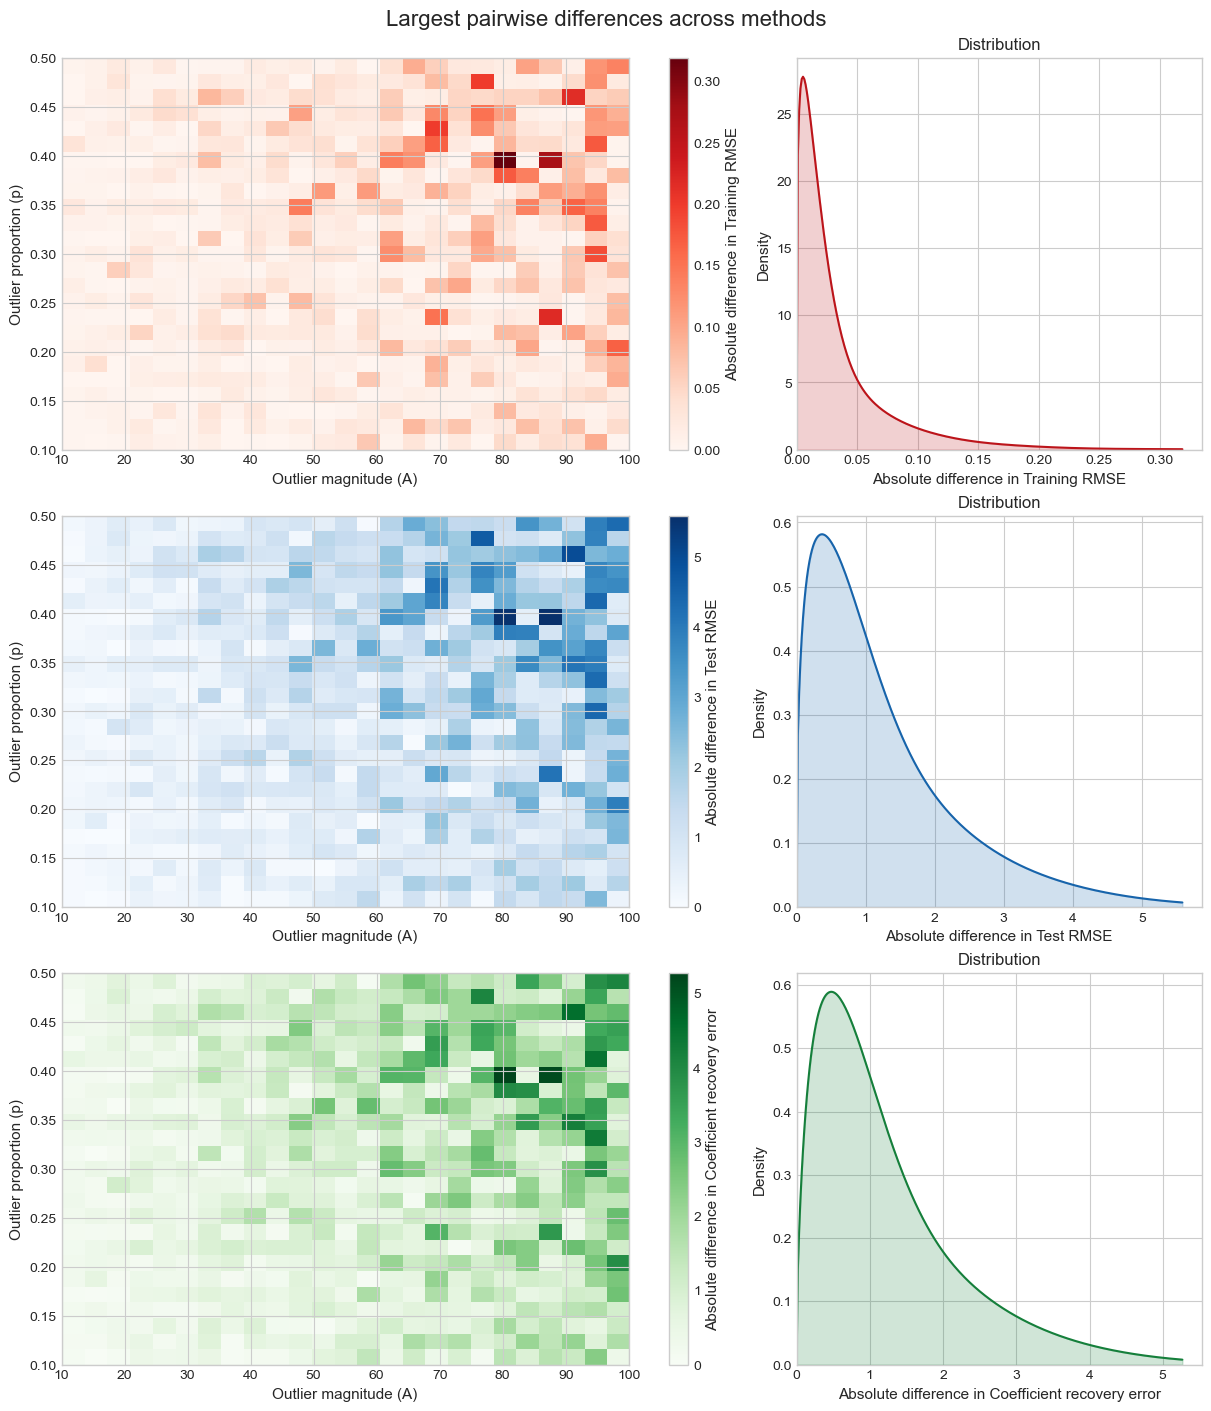

In [5]:
metric_plot_settings = (
    ("Training RMSE", "Reds"),
    ("Test RMSE", "Blues"),
    ("Coefficient recovery error", "Greens"),
)

fig, axes = plt.subplots(
    len(metric_plot_settings),
    2,
    figsize=(12, 14),
    constrained_layout=True,
    gridspec_kw={"width_ratios": [1.4, 1]},
)
fig.suptitle("Largest pairwise differences across methods", fontsize=16)

for (metric_name, cmap), (ax_heatmap, ax_kde) in zip(
    metric_plot_settings, axes, strict=False
):
    metric_values = np.stack(
        [statistics[method][metric_name] for method in method_names]
    )
    pairwise_differences = [
        np.abs(metric_values[i] - metric_values[j])
        for i in range(len(method_names))
        for j in range(i + 1, len(method_names))
    ]
    max_difference = np.maximum.reduce(pairwise_differences)
    difference_values = max_difference.ravel()
    value_range, density = gamma_kde(difference_values)
    color = plt.get_cmap(cmap)(0.8)

    image = ax_heatmap.imshow(
        max_difference,
        origin="lower",
        aspect="auto",
        extent=[A_range.min(), A_range.max(), p_range.min(), p_range.max()],
        cmap=cmap,
        interpolation="nearest",
        vmin=0,
    )
    ax_heatmap.set_xlabel("Outlier magnitude (A)", fontsize=11)
    ax_heatmap.set_ylabel("Outlier proportion (p)", fontsize=11)
    colorbar = fig.colorbar(image, ax=ax_heatmap)
    colorbar.set_label(f"Absolute difference in {metric_name}", fontsize=11)

    ax_kde.plot(value_range, density, color=color)
    ax_kde.fill_between(value_range, density, color=color, alpha=0.2)
    ax_kde.set_xlabel(f"Absolute difference in {metric_name}", fontsize=11)
    ax_kde.set_ylabel("Density", fontsize=11)
    ax_kde.set_title("Distribution", fontsize=12)
    ax_kde.set_xlim(left=0)
    ax_kde.set_ylim(bottom=0)

plt.show()